In [1]:
!pip install vadersentiment

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
analyzer=SentimentIntensityAnalyzer

In [3]:
import nltk
nltk.download('twitter_samples')

from nltk.corpus import twitter_samples
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

positive_reviews = twitter_samples.strings('positive_tweets.json')
negative_reviews = twitter_samples.strings('negative_tweets.json')

data = positive_reviews + negative_reviews

df = pd.DataFrame({
    'Text': data,
    'Actual_Sentiment': (
        ['Positive'] * len(positive_reviews) +
        ['Negative'] * len(negative_reviews)
    )
})

print(df.head())
print(df.shape)

[nltk_data] Downloading package twitter_samples to /root/nltk_data...
[nltk_data]   Unzipping corpora/twitter_samples.zip.


                                                Text Actual_Sentiment
0  #FollowFriday @France_Inte @PKuchly57 @Milipol...         Positive
1  @Lamb2ja Hey James! How odd :/ Please call our...         Positive
2  @DespiteOfficial we had a listen last night :)...         Positive
3                               @97sides CONGRATS :)         Positive
4  yeaaaah yippppy!!!  my accnt verified rqst has...         Positive
(10000, 2)


In [4]:
df['Sentiment_Score'] = df['Text'].apply(
    lambda text: analyzer.polarity_scores(text)['compound']
)

print(df[['Text', 'Sentiment_Score']].head())

                                                Text  Sentiment_Score
0  #FollowFriday @France_Inte @PKuchly57 @Milipol...           0.7579
1  @Lamb2ja Hey James! How odd :/ Please call our...           0.6229
2  @DespiteOfficial we had a listen last night :)...           0.7959
3                               @97sides CONGRATS :)           0.7983
4  yeaaaah yippppy!!!  my accnt verified rqst has...           0.7950


In [5]:
def get_sentiment(score):
    if score >= 0.05:
        return 'Positive'
    elif score <= -0.05:
        return 'Negative'
    else:
        return 'Neutral'

df['Predicted_Sentiment'] = df['Sentiment_Score'].apply(get_sentiment)

print(df[['Text', 'Sentiment_Score', 'Predicted_Sentiment']].head(10))

                                                Text  Sentiment_Score  \
0  #FollowFriday @France_Inte @PKuchly57 @Milipol...           0.7579   
1  @Lamb2ja Hey James! How odd :/ Please call our...           0.6229   
2  @DespiteOfficial we had a listen last night :)...           0.7959   
3                               @97sides CONGRATS :)           0.7983   
4  yeaaaah yippppy!!!  my accnt verified rqst has...           0.7950   
5  @BhaktisBanter @PallaviRuhail This one is irre...           0.6597   
6  We don't like to keep our lovely customers wai...           0.9466   
7  @Impatientraider On second thought, there’s ju...           0.2500   
8            Jgh , but we have to go to Bayan :D bye           0.7615   
9  As an act of mischievousness, am calling the E...           0.0000   

  Predicted_Sentiment  
0            Positive  
1            Positive  
2            Positive  
3            Positive  
4            Positive  
5            Positive  
6            Positive  
7   

In [6]:
sentiment_counts = df['Predicted_Sentiment'].value_counts()

print(sentiment_counts)

Predicted_Sentiment
Positive    5670
Negative    3648
Neutral      682
Name: count, dtype: int64


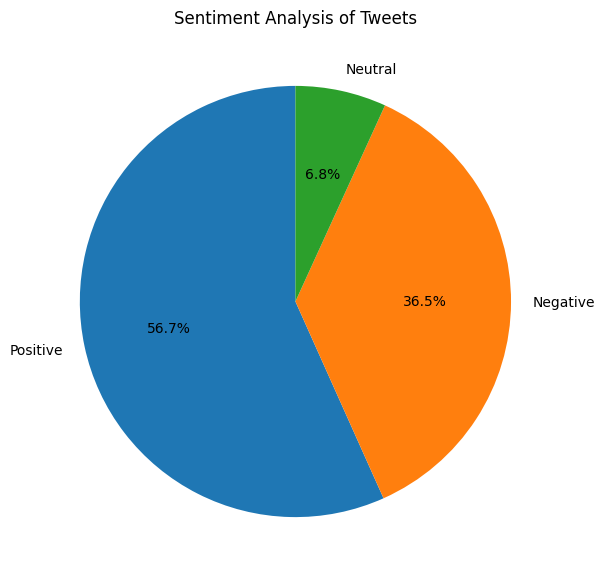

In [7]:
plt.figure(figsize=(7, 7))

plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Sentiment Analysis of Tweets')
plt.show()

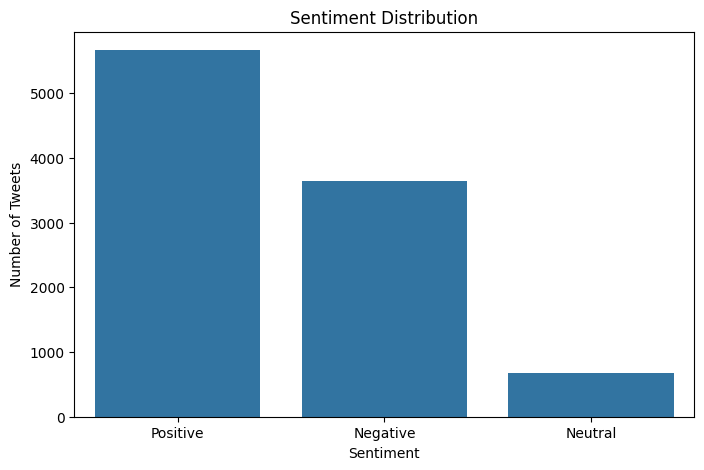

In [8]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Tweets')

plt.show()

In [9]:
from sklearn.metrics import classification_report

print(classification_report(
    df['Actual_Sentiment'],
    df['Predicted_Sentiment']
))

              precision    recall  f1-score   support

    Negative       0.93      0.68      0.79      5000
     Neutral       0.00      0.00      0.00         0
    Positive       0.80      0.91      0.86      5000

    accuracy                           0.80     10000
   macro avg       0.58      0.53      0.55     10000
weighted avg       0.87      0.80      0.82     10000



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [10]:
df.to_csv('CodeAlpha_Sentiment_Analysis.csv', index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


Conclusion – Sentiment Analysis

In this project, sentiment analysis was performed on 10,000 tweets using Python and the VADER Sentiment Analyzer.

Key Findings

* Total tweets analyzed: 10,000
* Positive tweets: 5,670 (56.7%)
* Negative tweets: 3,648 (36.5%)
* Neutral tweets: 682 (6.8%)

Tools and Technologies

* Python
* Pandas
* NLTK
* VADER Sentiment Analyzer
* Matplotlib
* Seaborn
* Google Colab

Result

The analysis shows that positive tweets represent the largest portion of the dataset. Pie charts and bar graphs were used to visualize sentiment distribution.

This project helped understand how Natural Language Processing (NLP) techniques can be used to identify public opinions from text data.